# BQ04–BQ05 — Tenure và churn concentration

Notebook này chỉ xử lý hai câu hỏi:

- **BQ04:** Khách hàng rời bỏ hiện tập trung ở giai đoạn tenure nào trong snapshot?
- **BQ05:** Vùng tập trung churn đó có ổn định khi dịch cửa sổ tenure hay chỉ là kết quả của cách chia nhóm?

> **Giới hạn diễn giải:** dữ liệu là snapshot. `MonthsInService` không phải dữ liệu survival/time-to-event, vì vậy notebook này không dùng churn rate để kết luận “xác suất churn tại tháng X”. Các kết quả dưới đây mô tả **churn volume/concentration**.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (14, 8),
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False
})


In [2]:
DATA_PATH = "../data/cell2cell_complete_cases.csv"

df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
display(df[["MonthsInService", "Churn"]].head())


Shape: (49752, 58)


,MonthsInService,Churn
0,61,Yes
1,58,Yes
2,60,No
3,59,No
4,53,Yes


In [3]:
# Chuẩn hóa target Churn về 0/1
print("Churn values:", df["Churn"].dropna().unique())

if df["Churn"].dtype == "object":
    churn_map = {
        "Yes": 1, "No": 0,
        "yes": 1, "no": 0,
        "Y": 1, "N": 0,
        "True": 1, "False": 0,
        "true": 1, "false": 0
    }
    df["Churn_bin"] = df["Churn"].map(churn_map)
else:
    df["Churn_bin"] = pd.to_numeric(df["Churn"], errors="coerce")

bq_df = df[["MonthsInService", "Churn_bin"]].copy()
bq_df["MonthsInService"] = pd.to_numeric(
    bq_df["MonthsInService"],
    errors="coerce"
)

print("\nMissing:")
print(bq_df.isna().sum())

print("\nMonthsInService:")
print(bq_df["MonthsInService"].describe())

print("\nChurn distribution:")
print(bq_df["Churn_bin"].value_counts(dropna=False).sort_index())

# Chỉ giữ quan sát hợp lệ cho BQ04–BQ05
bq_df = bq_df.dropna(subset=["MonthsInService", "Churn_bin"]).copy()
bq_df["MonthsInService"] = bq_df["MonthsInService"].astype(int)
bq_df["Churn_bin"] = bq_df["Churn_bin"].astype(int)

assert set(bq_df["Churn_bin"].unique()).issubset({0, 1})


Churn values: ['Yes' 'No']

Missing:
MonthsInService    0
Churn_bin          0
dtype: int64

MonthsInService:
count    49752.000000
mean        18.730805
std          9.739418
min          6.000000
25%         11.000000
50%         16.000000
75%         24.000000
max         61.000000
Name: MonthsInService, dtype: float64

Churn distribution:
Churn_bin
0    35507
1    14245
Name: count, dtype: int64


## BQ04 — Churn volume tập trung ở tenure nào?

Không chia tenure thành band cố định. Mỗi cột tương ứng với đúng một giá trị `MonthsInService`.

- **Đỏ:** số khách hàng churn.
- **Xám:** số khách hàng không churn.
- **Chiều cao toàn cột:** tổng số khách có tenure đó.

Biểu đồ trả lời câu hỏi về **quy mô churn quan sát được**, không phải hazard/xác suất churn theo thời gian.


In [4]:
# Tổng hợp theo từng tháng tenure
monthly = (
    bq_df
    .groupby("MonthsInService")
    .agg(
        customers=("Churn_bin", "size"),
        churners=("Churn_bin", "sum")
    )
    .reset_index()
    .sort_values("MonthsInService")
)

# Bổ sung tháng trống (nếu có) để trục thời gian và rolling window liên tục
min_month = int(bq_df["MonthsInService"].min())
max_month = int(bq_df["MonthsInService"].max())

all_months = pd.DataFrame({
    "MonthsInService": np.arange(min_month, max_month + 1)
})

monthly = (
    all_months
    .merge(monthly, on="MonthsInService", how="left")
    .fillna({"customers": 0, "churners": 0})
)

monthly["customers"] = monthly["customers"].astype(int)
monthly["churners"] = monthly["churners"].astype(int)
monthly["non_churners"] = monthly["customers"] - monthly["churners"]

display(monthly.head(12))


,MonthsInService,customers,churners,non_churners
0,6,727,142,585
1,7,2734,410,2324
2,8,2136,338,1798
3,9,2394,355,2039
4,10,2317,502,1815
5,11,3522,1569,1953
6,12,2668,1068,1600
7,13,2659,872,1787
8,14,2240,744,1496
9,15,1835,560,1275


In [5]:
# QA / reconciliation
total_customers = int(monthly["customers"].sum())
total_churners = int(monthly["churners"].sum())
total_non_churners = int(monthly["non_churners"].sum())

print(f"Tổng khách hàng : {total_customers:,}")
print(f"Rời bỏ          : {total_churners:,}")
print(f"Không rời bỏ    : {total_non_churners:,}")

assert total_customers == len(bq_df)
assert total_churners == int(bq_df["Churn_bin"].sum())
assert total_customers == total_churners + total_non_churners


Tổng khách hàng : 49,752
Rời bỏ          : 14,245
Không rời bỏ    : 35,507


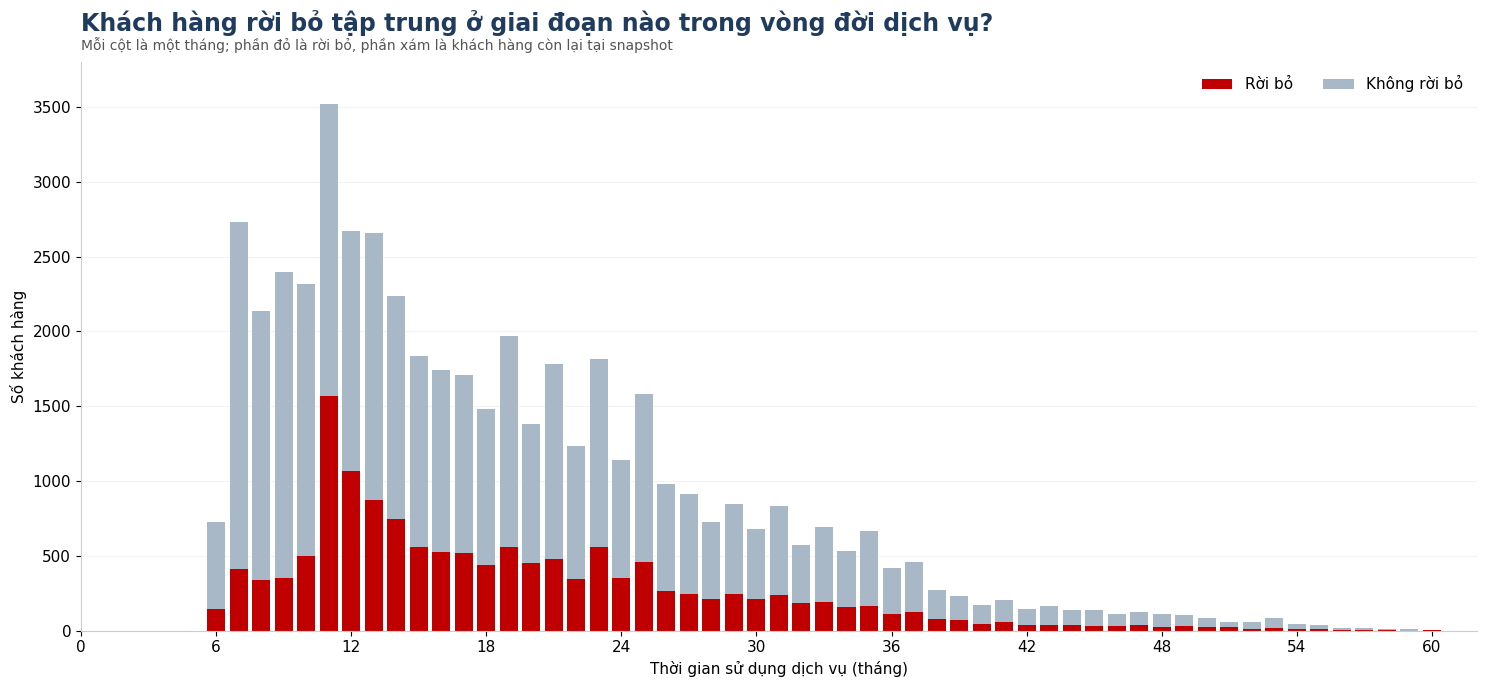

In [14]:
# Visual chính BQ04 — stacked bar theo từng tháng tenure
fig, ax = plt.subplots(figsize=(15, 7))

ax.bar(
    monthly["MonthsInService"],
    monthly["churners"],
    color="#C00000",
    width=0.8,
    label="Rời bỏ"
)

ax.bar(
    monthly["MonthsInService"],
    monthly["non_churners"],
    bottom=monthly["churners"],
    color="#A9B8C7",
    width=0.8,
    label="Không rời bỏ"
)

ax.set_title(
    "Khách hàng rời bỏ tập trung ở giai đoạn nào trong vòng đời dịch vụ?",
    loc="left",
    fontsize=17,
    fontweight="bold",
    color="#1F3B5D",
    pad=22
)

ax.text(
    0,
    1.02,
    (
        "Mỗi cột là một tháng; phần đỏ là rời bỏ, "
        "phần xám là khách hàng còn lại tại snapshot"
    ),
    transform=ax.transAxes,
    fontsize=10,
    color="#555555"
)

ax.set_xlabel("Thời gian sử dụng dịch vụ (tháng)")
ax.set_ylabel("Số khách hàng")

# Gốc trục tại (0, 0)
ax.set_xlim(0, max_month + 1)
ax.set_ylim(0, monthly["customers"].max() * 1.08)
ax.margins(x=0, y=0)

# Tick mỗi 6 tháng để tránh dày nhãn
ax.set_xticks(np.arange(0, max_month + 1, 6))

ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)

ax.spines["left"].set_color("#CCCCCC")
ax.spines["bottom"].set_color("#CCCCCC")

ax.legend(frameon=False, ncol=2, loc="upper right")

plt.tight_layout()
plt.show()


In [7]:
# Thống kê hỗ trợ BQ04 — chỉ dùng count / tenure distribution
peak_month = monthly.loc[monthly["churners"].idxmax()]

churn_tenure = bq_df.loc[
    bq_df["Churn_bin"] == 1,
    "MonthsInService"
]

q1 = churn_tenure.quantile(0.25)
median = churn_tenure.median()
q3 = churn_tenure.quantile(0.75)

print("BQ04 — Thống kê hỗ trợ")
print("-" * 40)
print(
    f"Tháng có nhiều churner nhất: "
    f"{int(peak_month['MonthsInService'])} tháng "
    f"({int(peak_month['churners']):,} churner)"
)
print(f"Q1 tenure của churner     : {q1:.0f} tháng")
print(f"Median tenure của churner : {median:.0f} tháng")
print(f"Q3 tenure của churner     : {q3:.0f} tháng")

top_months = (
    monthly
    .nlargest(10, "churners")
    [["MonthsInService", "customers", "churners"]]
    .reset_index(drop=True)
)

print("\nTop 10 tenure-month theo churn volume:")
display(top_months)


BQ04 — Thống kê hỗ trợ
----------------------------------------
Tháng có nhiều churner nhất: 11 tháng (1,569 churner)
Q1 tenure của churner     : 12 tháng
Median tenure của churner : 17 tháng
Q3 tenure của churner     : 24 tháng

Top 10 tenure-month theo churn volume:


,MonthsInService,customers,churners
0,11,3522,1569
1,12,2668,1068
2,13,2659,872
3,14,2240,744
4,23,1813,561
5,15,1835,560
6,19,1969,559
7,16,1739,529
8,17,1712,517
9,10,2317,502


### Cách kết luận BQ04

Chỉ kết luận theo **volume/concentration**:

> “Trong snapshot hiện tại, churn volume tập trung nhiều hơn ở một số vùng tenure nhất định.”

Không kết luận:

> “Khách ở tháng X có xác suất churn cao nhất.”

BQ05 sẽ kiểm tra xem vùng concentration quan sát được có còn xuất hiện khi cửa sổ tenure được dịch đi hay không.


## BQ05 — Vùng churn concentration có ổn định không?

Thay vì chọn một band cố định, dùng **rolling window**:

- `6–11`
- `7–12`
- `8–13`
- `9–14`
- ...

Mỗi điểm là **tổng churner trong 6 tháng liên tiếp**. Nếu nhiều cửa sổ lân cận cùng nằm ở vùng cao, dữ liệu hỗ trợ một **vùng concentration rộng** thay vì một breakpoint duy nhất.


In [8]:
# Rolling SUM 6 tháng
WINDOW = 6

rolling = monthly[
    ["MonthsInService", "customers", "churners"]
].copy()

rolling["churn_6m"] = (
    rolling["churners"]
    .rolling(window=WINDOW, min_periods=WINDOW)
    .sum()
)

rolling["customers_6m"] = (
    rolling["customers"]
    .rolling(window=WINDOW, min_periods=WINDOW)
    .sum()
)

rolling["window_end"] = rolling["MonthsInService"]
rolling["window_start"] = rolling["window_end"] - WINDOW + 1

rolling = rolling.dropna(subset=["churn_6m"]).copy()
rolling["churn_6m"] = rolling["churn_6m"].astype(int)
rolling["customers_6m"] = rolling["customers_6m"].astype(int)

display(
    rolling[
        ["window_start", "window_end", "customers_6m", "churn_6m"]
    ].head(12)
)


,window_start,window_end,customers_6m,churn_6m
5,6,11,13830,3316
6,7,12,15771,4242
7,8,13,15696,4704
8,9,14,15800,5110
9,10,15,15241,5315
10,11,16,14663,5342
11,12,17,12853,4290
12,13,18,11667,3659
13,14,19,10977,3346
14,15,20,10120,3055


In [9]:
# Top cửa sổ 6 tháng theo churn volume
top_windows = (
    rolling
    .nlargest(10, "churn_6m")
    [
        [
            "window_start",
            "window_end",
            "customers_6m",
            "churn_6m"
        ]
    ]
    .reset_index(drop=True)
)

top_windows["window"] = (
    top_windows["window_start"].astype(int).astype(str)
    + "–"
    + top_windows["window_end"].astype(int).astype(str)
)

display(
    top_windows[
        ["window", "customers_6m", "churn_6m"]
    ]
)


,window,customers_6m,churn_6m
0,11–16,14663,5342
1,10–15,15241,5315
2,9–14,15800,5110
3,8–13,15696,4704
4,12–17,12853,4290
5,7–12,15771,4242
6,13–18,11667,3659
7,14–19,10977,3346
8,6–11,13830,3316
9,15–20,10120,3055


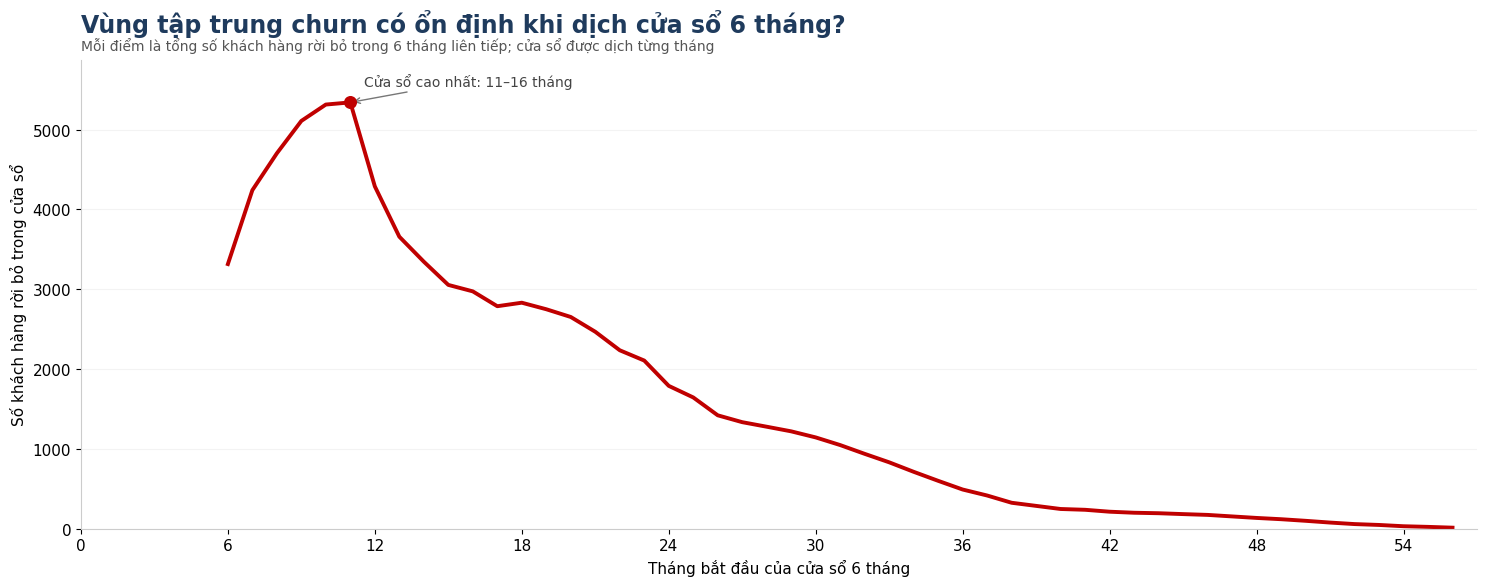

In [16]:
# Visual chính BQ05 — rolling 6-month churn count
fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(
    rolling["window_start"],
    rolling["churn_6m"],
    color="#C00000",
    linewidth=2.8
)

peak = rolling.loc[rolling["churn_6m"].idxmax()]

ax.scatter(
    peak["window_start"],
    peak["churn_6m"],
    color="#C00000",
    s=70,
    zorder=5
)

ax.annotate(
    (
        f"Cửa sổ cao nhất: "
        f"{int(peak['window_start'])}–{int(peak['window_end'])} tháng"
    ),
    xy=(peak["window_start"], peak["churn_6m"]),
    xytext=(10, 12),
    textcoords="offset points",
    fontsize=10,
    color="#444444",
    arrowprops={
        "arrowstyle": "->",
        "color": "#777777"
    }
)

ax.set_title(
    "Vùng tập trung churn có ổn định khi dịch cửa sổ 6 tháng?",
    loc="left",
    fontsize=17,
    fontweight="bold",
    color="#1F3B5D",
    pad=20
)

ax.text(
    0,
    1.02,
    (
        "Mỗi điểm là tổng số khách hàng rời bỏ trong 6 tháng liên tiếp; "
        "cửa sổ được dịch từng tháng"
    ),
    transform=ax.transAxes,
    fontsize=10,
    color="#555555"
)

ax.set_xlabel("Tháng bắt đầu của cửa sổ 6 tháng")
ax.set_ylabel("Số khách hàng rời bỏ trong cửa sổ")

# Gốc trục tại (0, 0)
ax.set_xlim(0, int(rolling["window_start"].max()) + 1)
ax.set_ylim(0, rolling["churn_6m"].max() * 1.10)
ax.margins(x=0, y=0)

ax.set_xticks(
    np.arange(
        0,
        int(rolling["window_start"].max()) + 1,
        6
    )
)

ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)

ax.spines["left"].set_color("#CCCCCC")
ax.spines["bottom"].set_color("#CCCCCC")

plt.tight_layout()
plt.show()


### Sensitivity theo độ rộng cửa sổ

Không overlay trực tiếp tổng churn của cửa sổ 3, 6 và 9 tháng vì tổng của cửa sổ dài hơn tự nhiên sẽ lớn hơn. Thay vào đó, chỉ so sánh **vị trí cửa sổ có churn volume cao nhất** ở từng độ rộng.


In [11]:
def peak_window_by_width(monthly_df, width):
    temp = monthly_df[
        ["MonthsInService", "customers", "churners"]
    ].copy()

    temp["window_churn"] = (
        temp["churners"]
        .rolling(window=width, min_periods=width)
        .sum()
    )

    temp["window_customers"] = (
        temp["customers"]
        .rolling(window=width, min_periods=width)
        .sum()
    )

    temp["window_end"] = temp["MonthsInService"]
    temp["window_start"] = temp["window_end"] - width + 1

    temp = temp.dropna(subset=["window_churn"])

    peak_row = temp.loc[temp["window_churn"].idxmax()]

    return {
        "window_width": width,
        "window_start": int(peak_row["window_start"]),
        "window_end": int(peak_row["window_end"]),
        "customers": int(peak_row["window_customers"]),
        "churners": int(peak_row["window_churn"])
    }


sensitivity = pd.DataFrame(
    [
        peak_window_by_width(monthly, 3),
        peak_window_by_width(monthly, 6),
        peak_window_by_width(monthly, 9)
    ]
)

sensitivity["peak_window"] = (
    sensitivity["window_start"].astype(str)
    + "–"
    + sensitivity["window_end"].astype(str)
)

display(
    sensitivity[
        [
            "window_width",
            "peak_window",
            "customers",
            "churners"
        ]
    ]
)


,window_width,peak_window,customers,churners
0,3,11–13,8849,3509
1,6,11–16,14663,5342
2,9,11–19,19826,6855


### Bootstrap stability cho cửa sổ 6 tháng

Resample riêng các churner và tìm lại cửa sổ 6 tháng có churn volume cao nhất. Nếu các cửa sổ chiến thắng lặp lại quanh cùng một vùng, kết luận về **vùng concentration** ổn định hơn. Nếu peak nhảy xa giữa nhiều vùng, không nên khóa một lifecycle window cụ thể.


In [12]:
rng = np.random.default_rng(42)

churn_months = (
    bq_df.loc[
        bq_df["Churn_bin"] == 1,
        "MonthsInService"
    ]
    .to_numpy()
)

months = np.arange(min_month, max_month + 1)

N_BOOT = 500
WINDOW = 6

bootstrap_peak_start = []

for _ in range(N_BOOT):
    sample = rng.choice(
        churn_months,
        size=len(churn_months),
        replace=True
    )

    counts = (
        pd.Series(sample)
        .value_counts()
        .reindex(months, fill_value=0)
        .sort_index()
    )

    roll = counts.rolling(
        window=WINDOW,
        min_periods=WINDOW
    ).sum()

    peak_end = int(roll.idxmax())
    peak_start = peak_end - WINDOW + 1

    bootstrap_peak_start.append(peak_start)

bootstrap_result = (
    pd.Series(
        bootstrap_peak_start,
        name="window_start"
    )
    .value_counts()
    .sort_values(ascending=False)
    .reset_index()
)

bootstrap_result.columns = [
    "window_start",
    "bootstrap_wins"
]

bootstrap_result["window_end"] = (
    bootstrap_result["window_start"] + WINDOW - 1
)

bootstrap_result["window"] = (
    bootstrap_result["window_start"].astype(str)
    + "–"
    + bootstrap_result["window_end"].astype(str)
)

display(
    bootstrap_result[
        ["window", "bootstrap_wins"]
    ].head(10)
)


,window,bootstrap_wins
0,11–16,400
1,10–15,100


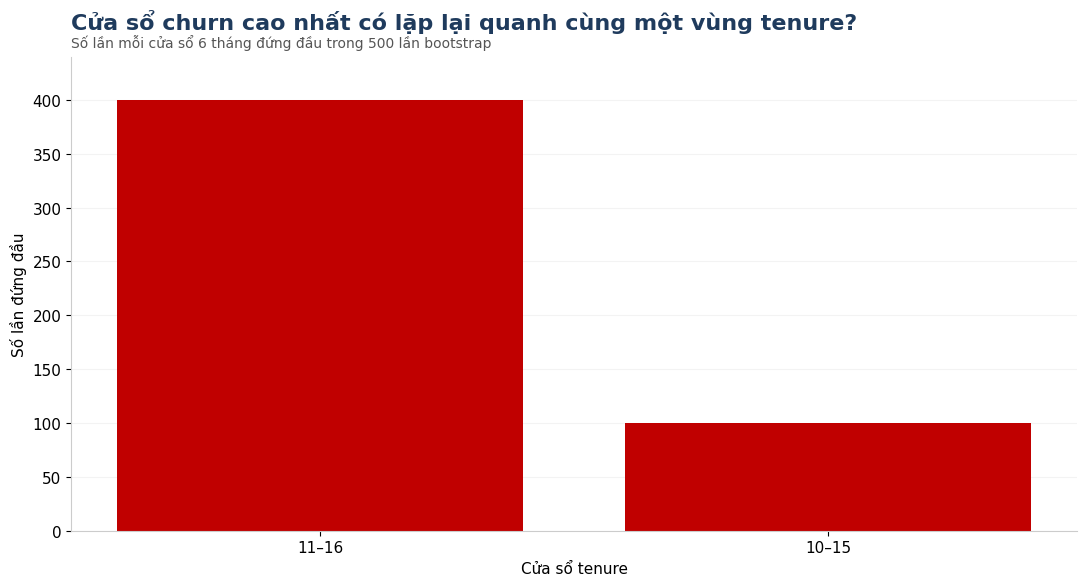

In [13]:
# Visual hỗ trợ BQ05 — bootstrap peak-window stability
plot_boot = bootstrap_result.head(10).copy()

fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    plot_boot["window"],
    plot_boot["bootstrap_wins"],
    color="#C00000"
)

ax.set_title(
    "Cửa sổ churn cao nhất có lặp lại quanh cùng một vùng tenure?",
    loc="left",
    fontsize=16,
    fontweight="bold",
    color="#1F3B5D",
    pad=20
)

ax.text(
    0,
    1.02,
    f"Số lần mỗi cửa sổ 6 tháng đứng đầu trong {N_BOOT} lần bootstrap",
    transform=ax.transAxes,
    fontsize=10,
    color="#555555"
)

ax.set_xlabel("Cửa sổ tenure")
ax.set_ylabel("Số lần đứng đầu")

ax.set_ylim(0, plot_boot["bootstrap_wins"].max() * 1.10)
ax.margins(y=0)

ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)

ax.spines["left"].set_color("#CCCCCC")
ax.spines["bottom"].set_color("#CCCCCC")

plt.tight_layout()
plt.show()


## Quy tắc kết luận BQ05

**Nếu rolling window 6 tháng tạo một vùng đỉnh rộng và sensitivity 3/6/9 tháng vẫn đặt peak quanh cùng khu vực:**

> **Supported:** churn volume tập trung trong một vùng tenure tương đối ổn định; dữ liệu ủng hộ một **vùng lifecycle cần chú ý**, không phải một breakpoint chính xác tại một tháng duy nhất.

**Nếu peak thay đổi mạnh khi đổi độ rộng cửa sổ hoặc bootstrap phân tán sang nhiều vùng xa nhau:**

> **Observed:** vị trí churn concentration nhạy với cách chọn cửa sổ; không khóa lifecycle trigger từ `MonthsInService`.

Trong cả hai trường hợp, không diễn giải kết quả thành “xác suất churn tại tháng X”, vì dữ liệu hiện tại là snapshot chứ không phải survival/time-to-event.
